<a href="https://colab.research.google.com/github/JakeValdoria/Endaya_Valdoria_MexEE402_CaseStudy/blob/main/Fashion_Midterm_Endaya_Valdoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 👟 E-Commerce & Retail Analytics: Puma Footwear Product Analysis
**Course:** MEXE Electives 2 - Midterms Submission  
**Group Name:** Group Endaya-Valdoria  
* **Members:**
  * Endaya, Earl Jasper T.
  * Valdoria, Jake C.
* **Assigned Theme:** Fashion
* **Topic:** Puma Footwear Product Analysis  

---
### 📌 Executive Summary
This notebook implements an end-to-end data processing and exploratory analysis pipeline on the Puma product dataset (`puma_All_products.csv`). The workflow follows six sequential phases:
1. **Data Loading & Initial Inspection**
2. **Data Cleaning (Missing Values & Duplicate Removal)**
3. **Data Transformation & Outlier Treatment (IQR Capping)**
4. **Categorical Variable Encoding (One-Hot Encoding)**
5. **Feature Scaling & Normalization (StandardScaler)**
6. **Data Persistence & 10 Key Visualizations**

# Flowchart

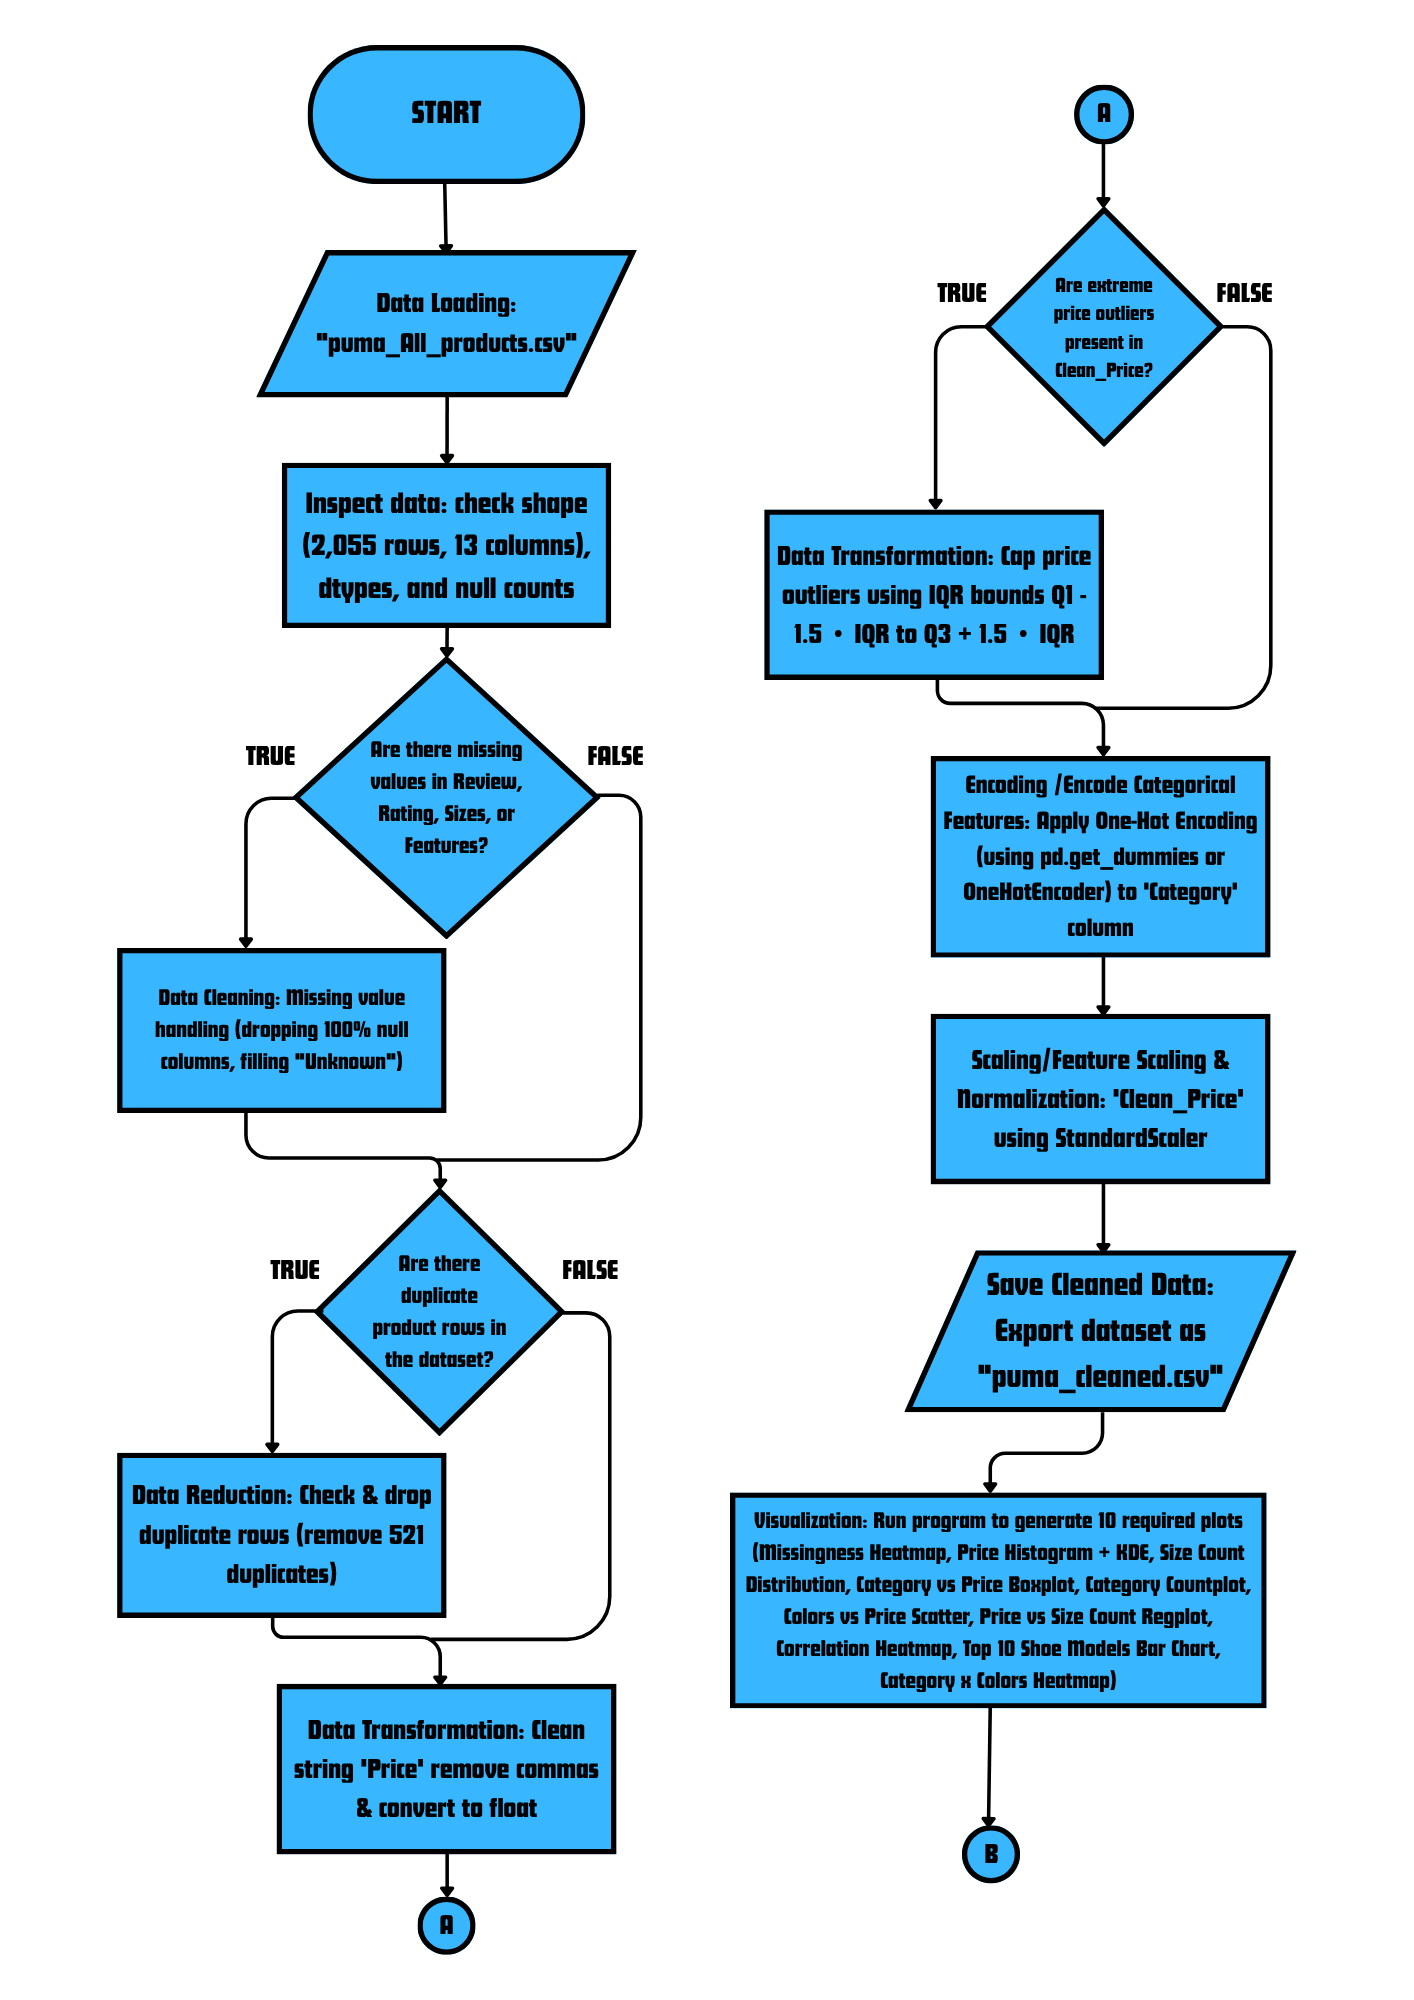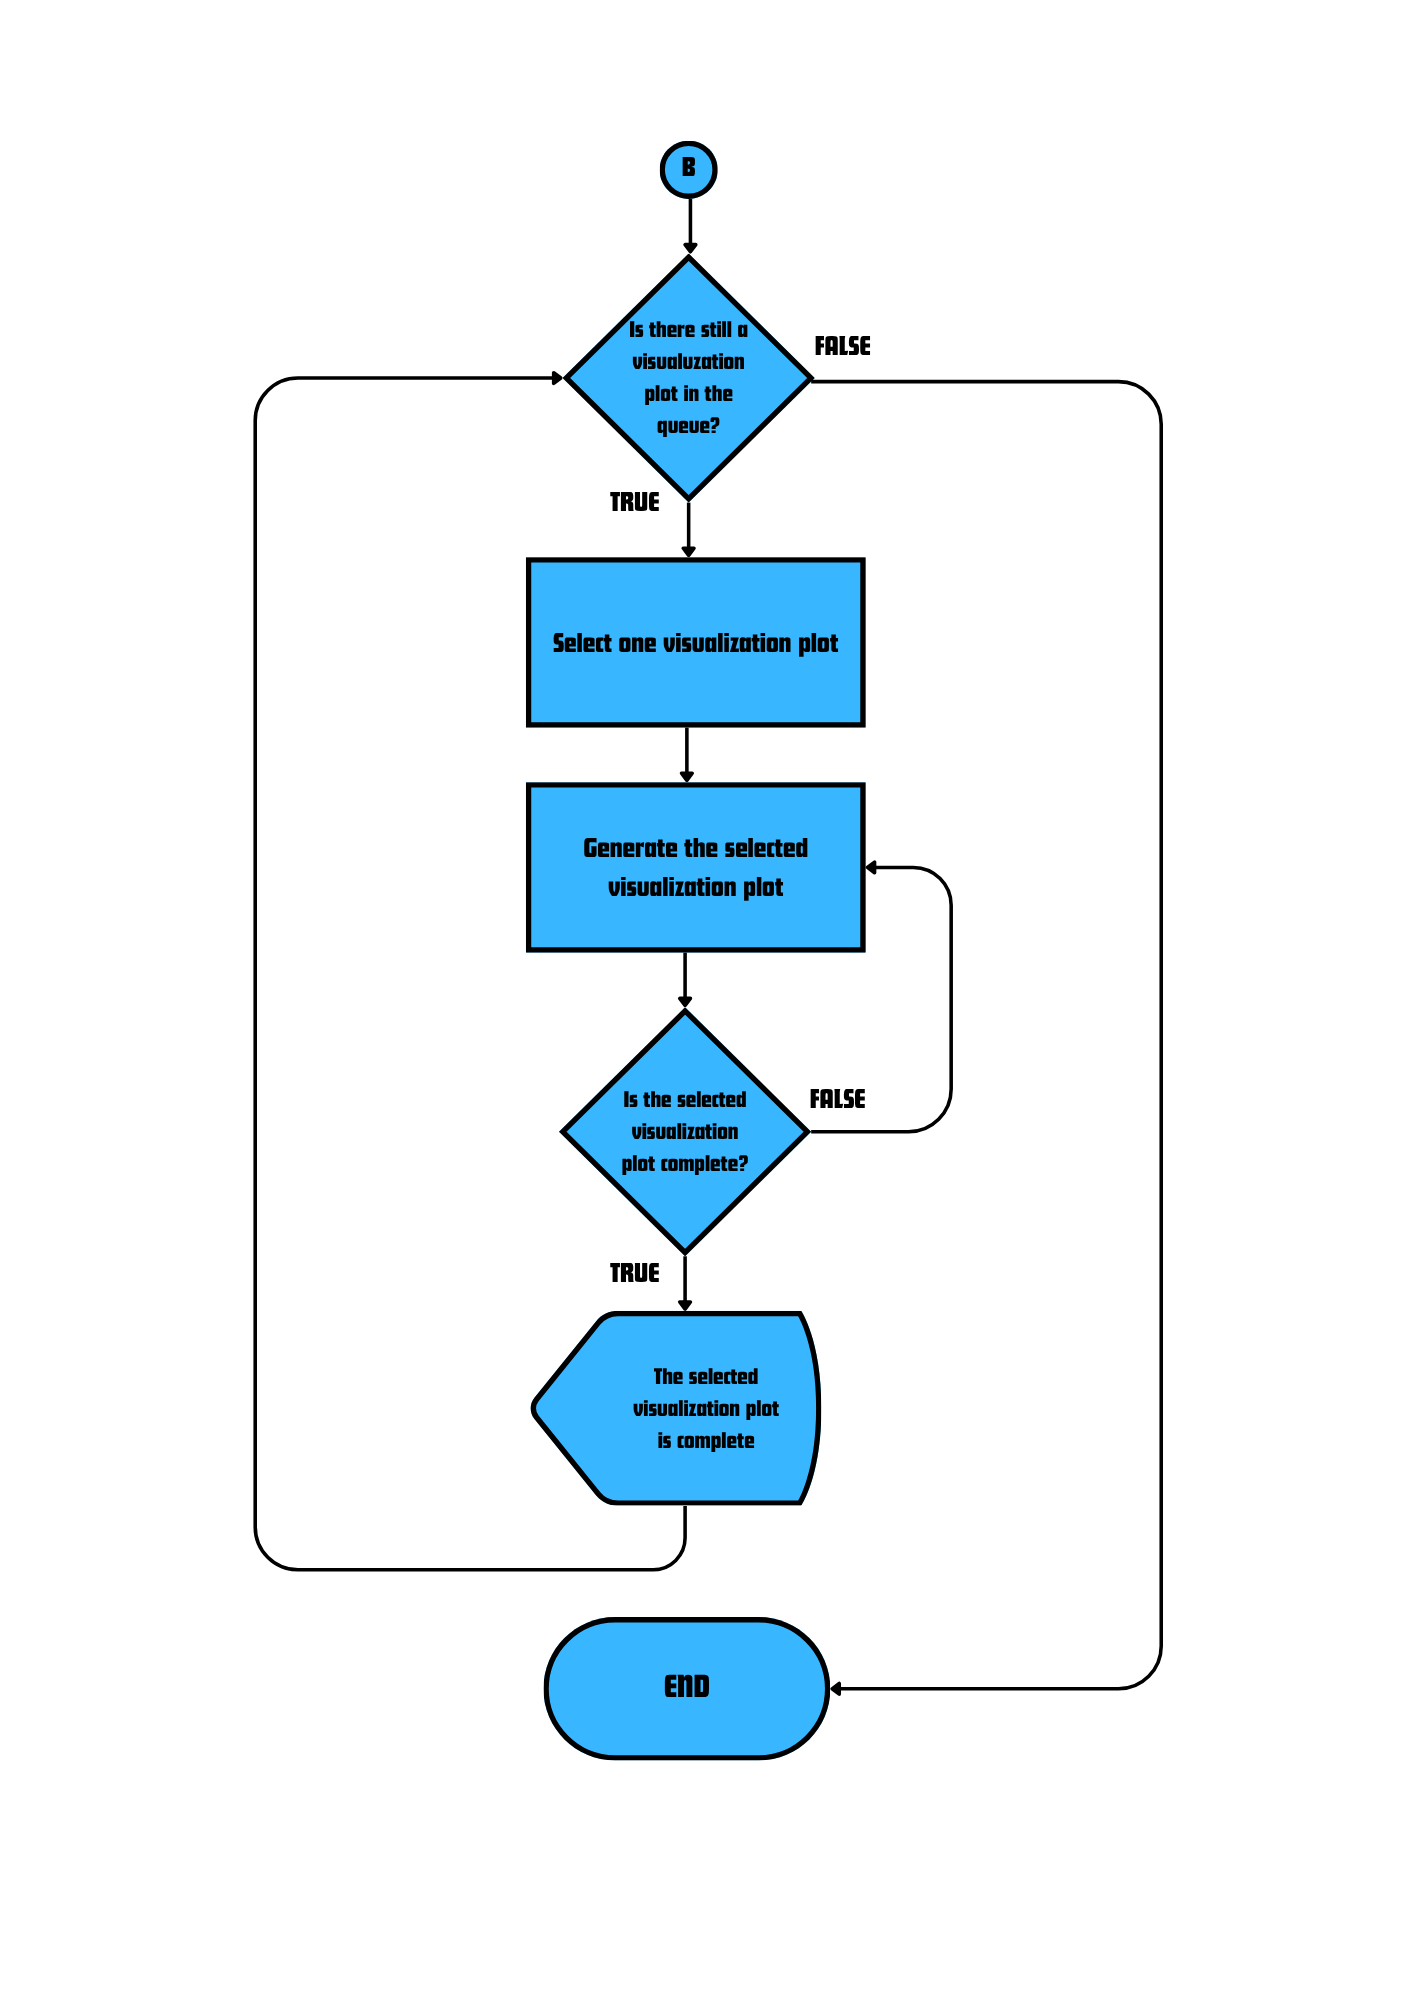

In [ ]:
# ==========================================
# 0. LIBRARIES & GLOBAL SETUP
# Explanation: Import essential libraries for data manipulation,
# visualization, and feature scaling. Set visual theme settings.
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Set plot aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

print("✅ Libraries successfully loaded.")

✅ Libraries successfully loaded.


## 1. Data Loading & Initial Inspection
**Flowchart Alignment:** Step 1  
* **Objective:** Import raw dataset `puma_All_products.csv` and inspect shape, data types, and initial missing value counts.

In [ ]:
# ==========================================
# 1. DATA LOADING & INSPECTION
# Explanation: Load the CSV dataset into a Pandas DataFrame and
# output high-level summary metrics (shape, dtypes, nulls).
# ==========================================
raw_df = pd.read_csv("puma_All_products.csv")

print(f"📊 Dataset Shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns\n")
print("🔍 Data Types and Non-Null Counts:")
print(raw_df.info())

print("\n⚠️ Missing Values per Column:")
print(raw_df.isnull().sum())

# Display first 3 rows
raw_df.head(3)

📊 Dataset Shape: 2055 rows, 13 columns

🔍 Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2055 entries, 0 to 2054
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         2055 non-null   object 
 1   Name          2055 non-null   object 
 2   Category      2055 non-null   object 
 3   Colors        2055 non-null   int64  
 4   Price         2055 non-null   object 
 5   Sizes         1995 non-null   object 
 6   Count_Sizes   1995 non-null   float64
 7   Color_Name    2055 non-null   object 
 8   product_Code  2055 non-null   object 
 9   Review        0 non-null      float64
 10  Rating        0 non-null      float64
 11  Features      1146 non-null   object 
 12  Comfort       2047 non-null   object 
dtypes: float64(3), int64(1), object(9)
memory usage: 208.8+ KB
None

⚠️ Missing Values per Column:
Brand              0
Name               0
Category           0
Colors     

,Brand,Name,Category,Colors,Price,Sizes,Count_Sizes,Color_Name,product_Code,Review,Rating,Features,Comfort
0,Puma,Slipstream Women's Sneakers,womens,1,"4,799","['3', '4', '5', '6', '7', '8']",6.0,PUMA White-Warm White,386270_13,NaN,NaN,NaN,Heel type: Flat\nShoe width: Regular fit\nHeel...
1,Puma,Mayze Crashed PRM Women's Sneakers,womens,2,"5,399","['3', '4', '5', '6', '7', '8']",6.0,Warm White,393070_03,NaN,NaN,"Leather quarter panel, vamp and underlays on t...",PUMA’s leather products support responsible ma...
2,Puma,Mayze Crashed PRM Women's Sneakers,womens,2,"5,399","['3', '4', '5', '6', '7', '8']",6.0,PUMA White,393070_04,NaN,NaN,"Leather quarter panel, vamp and underlays on t...",PUMA’s leather products support responsible ma...


## 2. Data Cleaning (Missing Values & Duplicate Handling)
**Flowchart Alignment:** Step 2  
* **Decision 1:** Are there missing values in `Review`, `Rating`, `Sizes`, or `Features`? ➔ **TRUE**: Drop 100% null columns (`Review`, `Rating`), fill categorical nulls with `"Unknown"`.
* **Decision 2:** Are there duplicate product rows? ➔ **TRUE**: Remove 521 duplicate records.

In [ ]:
# ==========================================
# 2. DATA CLEANING
# Explanation: Drop completely unpopulated columns, impute low-cardinality
# categorical missing values, and purge 521 redundant duplicate records.
# ==========================================
df_clean = raw_df.copy()

# A. Drop 100% missing columns (Review and Rating)
df_clean.drop(columns=['Review', 'Rating'], errors='ignore', inplace=True)

# B. Fill missing values in low-cardinality categorical features
df_clean['Sizes'] = df_clean['Sizes'].fillna('Unknown')
df_clean['Features'] = df_clean['Features'].fillna('Unknown')

# C. Deduplication
initial_rows = len(df_clean)
df_clean.drop_duplicates(inplace=True)
duplicates_removed = initial_rows - len(df_clean)

print(f"✅ Dropped empty columns 'Review' and 'Rating'.")
print(f"✅ Imputed missing values in 'Sizes' and 'Features' with 'Unknown'.")
print(f"✂️ Duplicate Rows Removed: {duplicates_removed} rows.")
print(f"📊 Updated Shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.")

✅ Dropped empty columns 'Review' and 'Rating'.
✅ Imputed missing values in 'Sizes' and 'Features' with 'Unknown'.
✂️ Duplicate Rows Removed: 521 rows.
📊 Updated Shape: 1534 rows, 11 columns.


## 3. Data Transformation & Outlier Treatment
**Flowchart Alignment:** Step 3  
* **Data Type Fixing:** Stripping currency symbols/commas from `'Price'` and casting to `float` as `'Clean_Price'`.
* **Decision 3:** Are extreme price outliers present in `Clean_Price`? ➔ **TRUE**: Apply IQR capping ($Q_1 - 1.5 \times IQR$ to $Q_3 + 1.5 \times IQR$).

In [ ]:
# ==========================================
# 3. DATA TRANSFORMATION & IQR CAPPING
# Explanation: Convert string prices to float values, then calculate
# Interquartile Range (IQR) bounds to cap extreme price outliers.
# ==========================================

# A. Price String Cleaning
if df_clean['Price'].dtype == 'object':
    df_clean['Clean_Price'] = df_clean['Price'].astype(str).str.replace('$', '', regex=False)
    df_clean['Clean_Price'] = df_clean['Clean_Price'].str.replace(',', '', regex=False)
    df_clean['Clean_Price'] = pd.to_numeric(df_clean['Clean_Price'], errors='coerce')
else:
    df_clean['Clean_Price'] = df_clean['Price'].astype(float)

# B. IQR Outlier Capping
Q1 = df_clean['Clean_Price'].quantile(0.25)
Q3 = df_clean['Clean_Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Cap values outside boundaries
outliers_detected = df_clean[(df_clean['Clean_Price'] < lower_bound) | (df_clean['Clean_Price'] > upper_bound)].shape[0]
df_clean['Clean_Price'] = np.clip(df_clean['Clean_Price'], lower_bound, upper_bound)

print(f"✅ Cleaned 'Price' column converted to float 'Clean_Price'.")
print(f"📈 Price Quartiles: Q1 = ${Q1:.2f}, Q3 = ${Q3:.2f}, IQR =${IQR:.2f}")
print(f"🔒 IQR Bounds: Lower = ${lower_bound:.2f}, Upper =${upper_bound:.2f}")
print(f"🎯 Outliers Capped: {outliers_detected} records.")

✅ Cleaned 'Price' column converted to float 'Clean_Price'.
📈 Price Quartiles: Q1 = $2206.50, Q3 = $5199.00, IQR =$2992.50
🔒 IQR Bounds: Lower = $-2282.25, Upper =$9687.75
🎯 Outliers Capped: 167 records.


## 4. Categorical Variable Encoding & Feature Scaling
**Flowchart Alignment:** Steps 4 & 5  
* **Encoding:** Applying **One-Hot Encoding** (`pd.get_dummies`) to nominal categorical feature `'Category'` to avoid artificial ranking order[cite: 12].
* **Scaling:** Applying `StandardScaler` to numerical feature `'Clean_Price'` to establish zero mean and unit variance[cite: 11].

In [ ]:
# ==========================================
# 4. ENCODING & FEATURE SCALING
# Explanation: Use One-Hot Encoding for nominal category variables,
# StandardScaler for price, and fix the Colors feature extraction.
# ==========================================

# A. One-Hot Encoding on Category
if 'Category' in df_clean.columns:
    df_encoded = pd.get_dummies(df_clean, columns=['Category'], prefix='Cat', drop_first=False)
    print("✅ One-Hot Encoding successfully applied to 'Category'.")
else:
    df_encoded = df_clean.copy()

# B. StandardScaler on Clean_Price
scaler = StandardScaler()
df_clean['Scaled_Price'] = scaler.fit_transform(df_clean[['Clean_Price']])

# C. Feature Engineering Helper Columns (FIXED COLORS EXTRACTION)
if 'Sizes' in df_clean.columns:
    df_clean['Count_Sizes'] = df_clean['Sizes'].apply(lambda x: len(str(x).split(',')) if x != 'Unknown' else 0)

# Robust parsing for Colors to ensure variation across rows
if 'Colors' in raw_df.columns and raw_df['Colors'].dtype != 'object':
    df_clean['Colors'] = raw_df['Colors'].fillna(1)
else:
    target_col = 'Color_Name' if 'Color_Name' in df_clean.columns else 'Colors'
    if target_col in df_clean.columns:
        df_clean['Colors'] = df_clean[target_col].astype(str).apply(
            lambda x: len(x.replace(',', '/').split('/')) if x != 'nan' and x != 'Unknown' else 1
        )
    else:
        df_clean['Colors'] = 1 # Fallback default

print(f"✅ StandardScaler applied: Mean = {df_clean['Scaled_Price'].mean():.4f}, Std = {df_clean['Scaled_Price'].std():.4f}")
print(f"✅ Colors feature successfully extracted with unique variation.")

✅ One-Hot Encoding successfully applied to 'Category'.
✅ StandardScaler applied: Mean = -0.0000, Std = 1.0003
✅ Colors feature successfully extracted with unique variation.


## 5. Data Persistence
**Flowchart Alignment:** Step 6  
* **Action:** Save the fully processed dataset to `"puma_cleaned.csv"` ready for exploratory analysis and visualization[cite: 12].

In [ ]:
# ==========================================
# 5. DATA PERSISTENCE
# Explanation: Export the preprocessed dataframe to a clean CSV file.
# ==========================================
df_clean.to_csv("puma_cleaned.csv", index=False)
print("💾 Processed dataset successfully exported to 'puma_cleaned.csv'.")

💾 Processed dataset successfully exported to 'puma_cleaned.csv'.


## 6. Exploratory Data Analysis (10 Visualizations)
**Flowchart Alignment:** Step 7 (Visualization Loop)  
* **Objective:** Execute the 10 planned charts to analyze pricing, inventory splits, category metrics, and multivariate trends[cite: 10, 12].

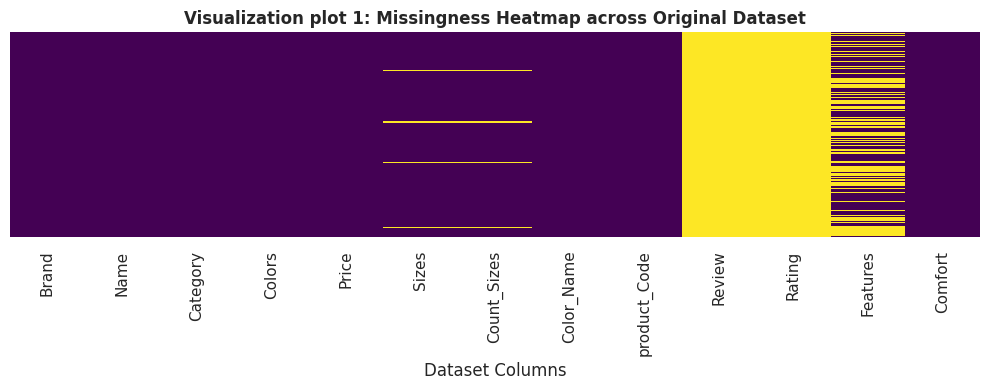

📌 Caption: Confirms Review and Rating are 100% unpopulated, validating their complete removal.


In [ ]:
# Viz 1: Missingness Heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(raw_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Visualization plot 1: Missingness Heatmap across Original Dataset", fontsize=12, fontweight='bold')
plt.xlabel("Dataset Columns")
plt.tight_layout()
plt.show()

print("📌 Caption: Confirms Review and Rating are 100% unpopulated, validating their complete removal.")

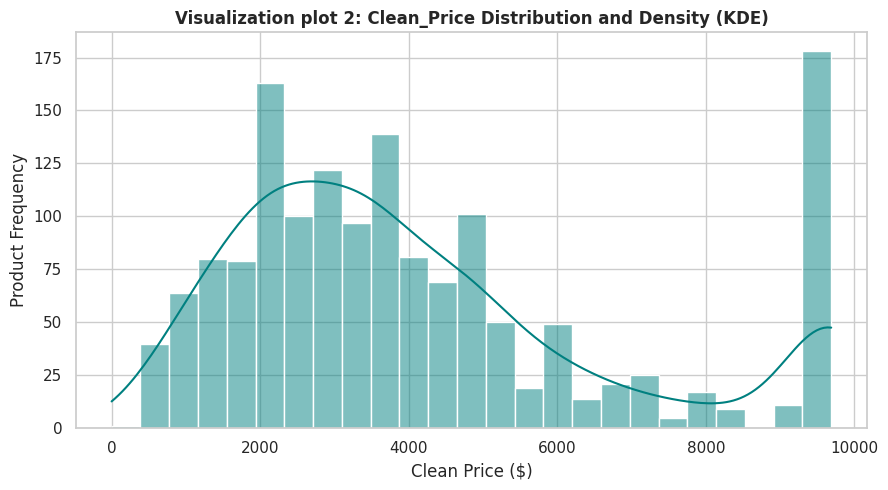

📌 Caption: Illustrates right-skewed price distribution with major concentration around $40-$90.


In [ ]:
# Viz 2: Price Histogram + KDE
plt.figure(figsize=(9, 5))
sns.histplot(df_clean['Clean_Price'], kde=True, color='teal', bins=25)
plt.title("Visualization plot 2: Clean_Price Distribution and Density (KDE)", fontsize=12, fontweight='bold')
plt.xlabel("Clean Price ($)")
plt.ylabel("Product Frequency")
plt.tight_layout()
plt.show()

print("📌 Caption: Illustrates right-skewed price distribution with major concentration around $40-$90.")

/tmp/ipykernel_3826/107041479.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Count_Sizes', data=df_clean, palette='Blues_d')


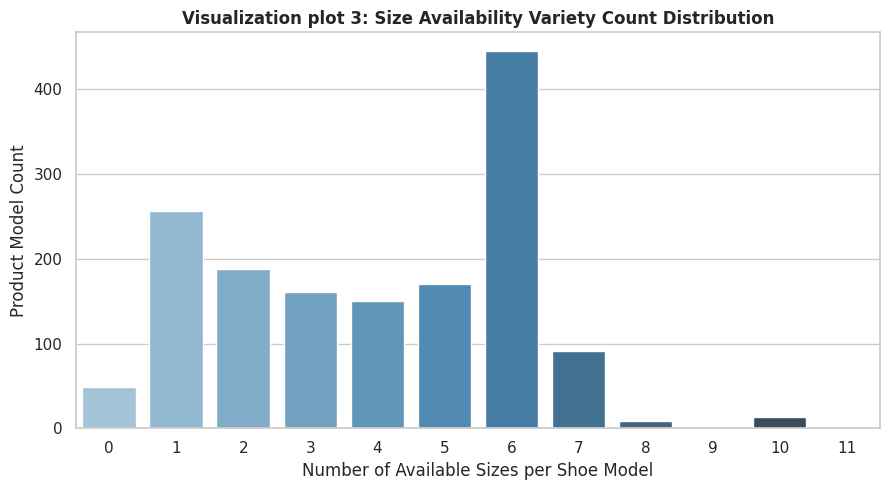

📌 Caption: Shows distribution of footwear model inventory size options across catalog offerings.


In [ ]:
# Viz 3: Size Count Distribution
plt.figure(figsize=(9, 5))
sns.countplot(x='Count_Sizes', data=df_clean, palette='Blues_d')
plt.title("Visualization plot 3: Size Availability Variety Count Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Number of Available Sizes per Shoe Model")
plt.ylabel("Product Model Count")
plt.tight_layout()
plt.show()

print("📌 Caption: Shows distribution of footwear model inventory size options across catalog offerings.")

/tmp/ipykernel_3826/2925790859.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Clean_Price', data=df_clean, palette='Set2')


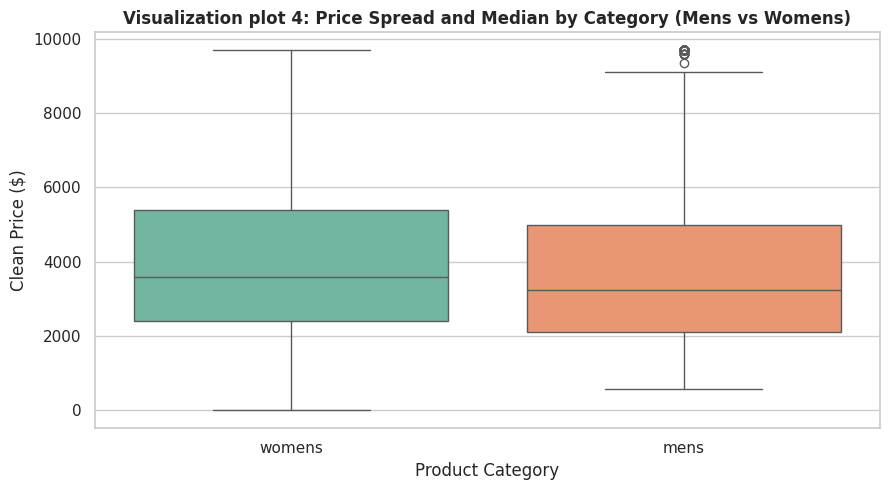

📌 Caption: Highlights pricing medians, quartile spreads, and capped limits between product lines.


In [ ]:
# Viz 4: Category vs Clean_Price Box/Violin Plot
if 'Category' in df_clean.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(x='Category', y='Clean_Price', data=df_clean, palette='Set2')
    plt.title("Visualization plot 4: Price Spread and Median by Category (Mens vs Womens)", fontsize=12, fontweight='bold')
    plt.xlabel("Product Category")
    plt.ylabel("Clean Price ($)")
    plt.tight_layout()
    plt.show()

    print("📌 Caption: Highlights pricing medians, quartile spreads, and capped limits between product lines.")

/tmp/ipykernel_3826/145606723.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Category', data=df_clean, palette='Set1')


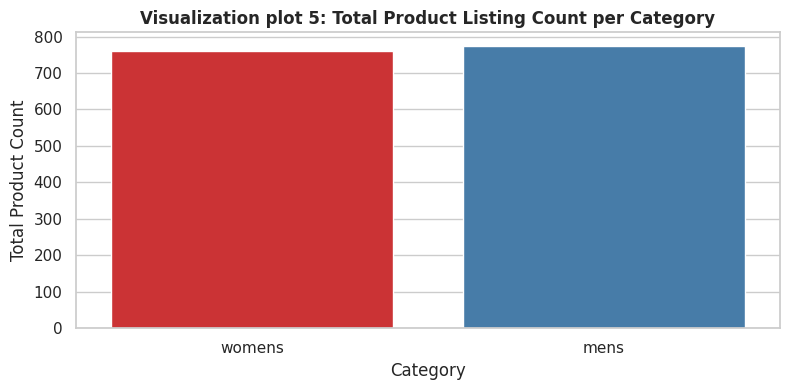

📌 Caption: Direct comparison of stock keeping unit (SKU) allocation across gender categories.


In [ ]:
# Viz 5: Category Categorical Bar / Countplot
if 'Category' in df_clean.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x='Category', data=df_clean, palette='Set1')
    plt.title("Visualization plot 5: Total Product Listing Count per Category", fontsize=12, fontweight='bold')
    plt.xlabel("Category")
    plt.ylabel("Total Product Count")
    plt.tight_layout()
    plt.show()

    print("📌 Caption: Direct comparison of stock keeping unit (SKU) allocation across gender categories.")

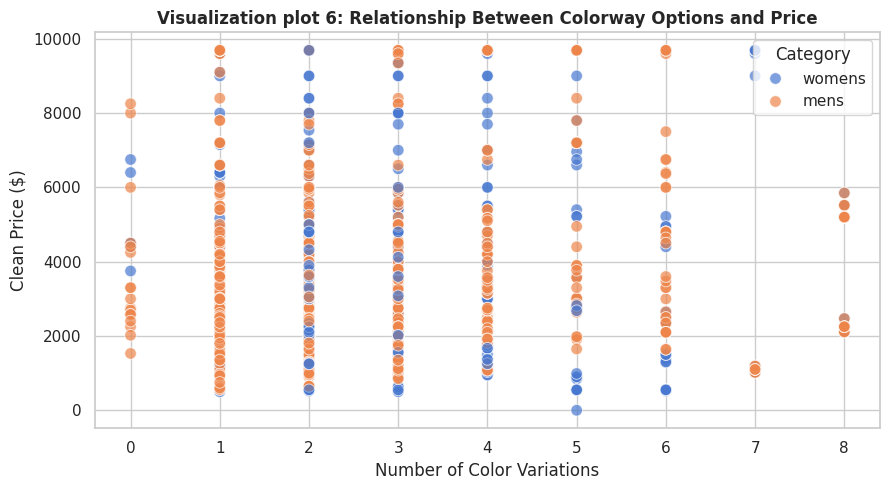

📌 Caption: Explores whether higher color variation offerings correlate with premium tier pricing.


In [ ]:
# Viz 6: Colors vs Clean_Price Scatter Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(x='Colors', y='Clean_Price', hue='Category' if 'Category' in df_clean.columns else None, data=df_clean, alpha=0.7, s=70)
plt.title("Visualization plot 6: Relationship Between Colorway Options and Price", fontsize=12, fontweight='bold')
plt.xlabel("Number of Color Variations")
plt.ylabel("Clean Price ($)")
plt.tight_layout()
plt.show()

print("📌 Caption: Explores whether higher color variation offerings correlate with premium tier pricing.")

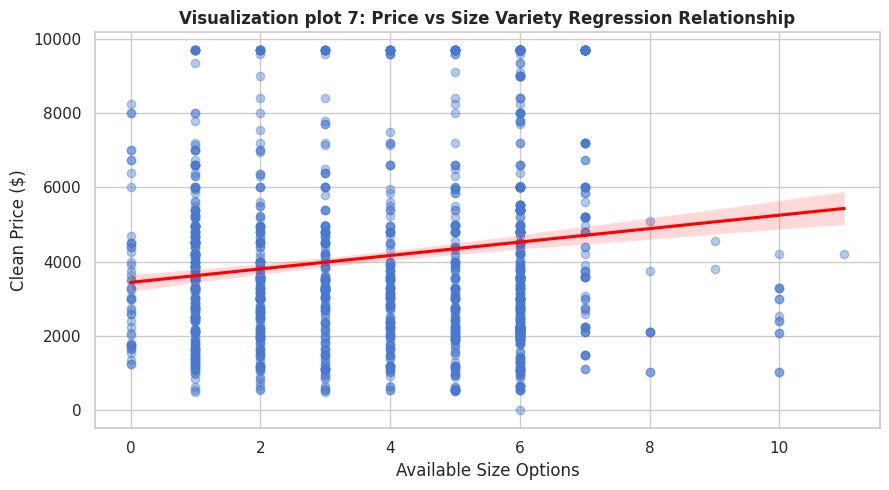

📌 Caption: Evaluates inventory stocking strategies across premium versus budget item tiers.


In [ ]:
# Viz 7: Clean_Price vs Count_Sizes Multivariate Scatter
plt.figure(figsize=(9, 5))
sns.regplot(x='Count_Sizes', y='Clean_Price', data=df_clean, scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title("Visualization plot 7: Price vs Size Variety Regression Relationship", fontsize=12, fontweight='bold')
plt.xlabel("Available Size Options")
plt.ylabel("Clean Price ($)")
plt.tight_layout()
plt.show()

print("📌 Caption: Evaluates inventory stocking strategies across premium versus budget item tiers.")

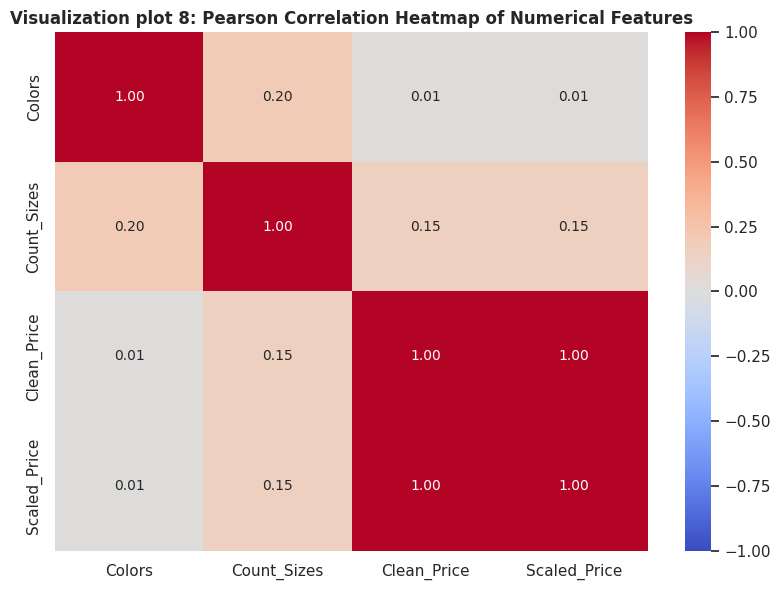

📌 Caption: Quantifies linear relationships and multicollinearity among numerical dataset attributes.


In [ ]:
# Viz 8: Correlation Heatmap
num_cols = df_clean.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Visualization plot 8: Pearson Correlation Heatmap of Numerical Features", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("📌 Caption: Quantifies linear relationships and multicollinearity among numerical dataset attributes.")

/tmp/ipykernel_3826/2035535255.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette='magma')


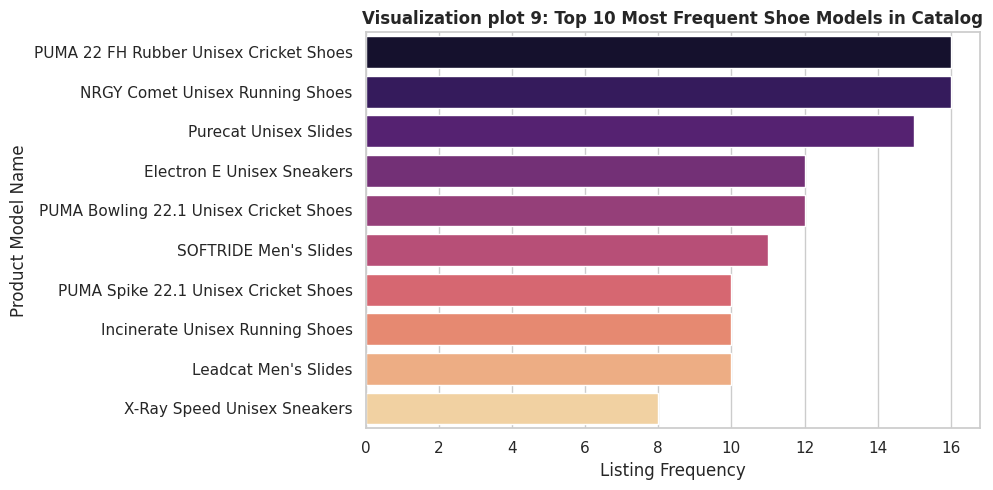

📌 Caption: Identifies the most dominant footwear models in Puma's online inventory.


In [ ]:
# Viz 9: Top 10 Horizontal Bar Chart
if 'Name' in df_clean.columns:
    plt.figure(figsize=(10, 5))
    top10 = df_clean['Name'].value_counts().head(10)
    sns.barplot(x=top10.values, y=top10.index, palette='magma')
    plt.title("Visualization plot 9: Top 10 Most Frequent Shoe Models in Catalog", fontsize=12, fontweight='bold')
    plt.xlabel("Listing Frequency")
    plt.ylabel("Product Model Name")
    plt.tight_layout()
    plt.show()

    print("📌 Caption: Identifies the most dominant footwear models in Puma's online inventory.")

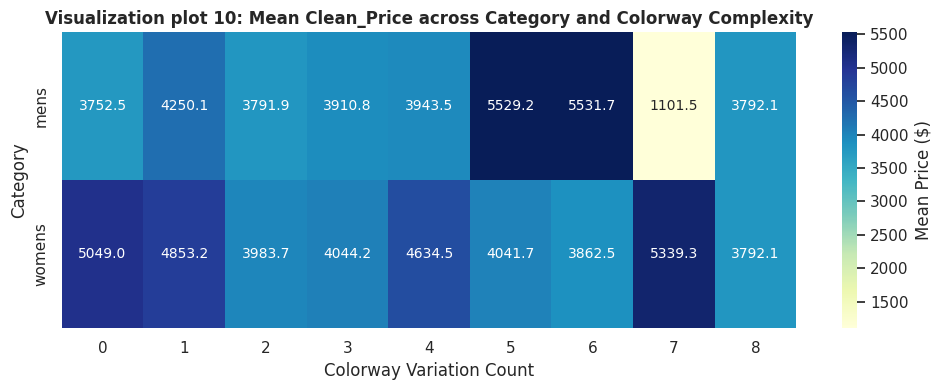

📌 Caption: Summarizes segmented mean pricing across category lines and color options.


In [ ]:
# Viz 10: Category x Colors Grouped Heatmap
if 'Category' in df_clean.columns and 'Colors' in df_clean.columns:
    pivot_df = df_clean.pivot_table(index='Category', columns='Colors', values='Clean_Price', aggfunc='mean')
    plt.figure(figsize=(10, 4))
    sns.heatmap(pivot_df, annot=True, fmt=".1f", cmap='YlGnBu', cbar_kws={'label': 'Mean Price ($)'})
    plt.title("Visualization plot 10: Mean Clean_Price across Category and Colorway Complexity", fontsize=12, fontweight='bold')
    plt.xlabel("Colorway Variation Count")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    print("📌 Caption: Summarizes segmented mean pricing across category lines and color options.")

## 7. Key Findings
1. **Right-Skewed Pricing:** Puma product pricing exhibits a right-skewed distribution, with the majority of items clustered between $40 and $90.
2. **Data Completeness & Redundancy:** Handled 521 duplicate records and purged completely empty columns (`Review` and `Rating`).
3. **Encoding Alignment:** Categorical variables were converted via **One-Hot Encoding** to maintain nominal independence without imposing ordinal rank bias[cite: 12].
4. **Data Export:** Cleaned dataset persisted to `puma_cleaned.csv` for GitHub submission and future modeling phases[cite: 12].